In [1]:
# Cell 1: Libraries and Environment Initialization
import os
import sys
import numpy as np
import xarray as xr
import rioxarray
import geopandas as gpd
import torch
import ee

# 1. Initialize Google Earth Engine with your registered project
PROJECT_ID = 'additional-project-511308'
try:
    ee.Initialize(project=PROJECT_ID)
    print(f"Earth Engine initialized successfully with project: {PROJECT_ID}")
except Exception as e:
    print(f"Earth Engine initialization failed: {e}")

# 2. Verify GPU availability for later model training
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"PyTorch Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")

# 3. Base directories setup
BASE_DIR = os.path.abspath('..')
DATA_RAW = os.path.join(BASE_DIR, 'data', 'raw')
DATA_PROCESSED = os.path.join(BASE_DIR, 'data', 'processed')

os.makedirs(DATA_RAW, exist_ok=True)
os.makedirs(DATA_PROCESSED, exist_ok=True)
print(f"Working directories confirmed:\n  Raw: {DATA_RAW}\n  Processed: {DATA_PROCESSED}")

/home/mahtab/miniconda3/envs/adp/lib/python3.10/site-packages/google/api_core/_python_version_support.py:239: FutureWarning: You are using a Python version (3.10.22) past its end of life. Google will update google.api_core with critical bug fixes on a best-effort basis, but not with any other fixes or features. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)
*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Earth Engine initialized successfully with project: additional-project-511308
PyTorch Device: cuda
GPU Name: NVIDIA GeForce RTX 4050 Laptop GPU
Working directories confirmed:
  Raw: /home/mahtab/ADP/data/raw
  Processed: /home/mahtab/ADP/data/processed


/tmp/ipykernel_103988/1114585466.py:15: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf_mainland = exploded[exploded.geometry.area > 10.0].dissolve()


Exact Mainland India Extent (Verified):
  South (Kanyakumari, Tamil Nadu) : 8.0772° N
  North (Ladakh / Siachen)        : 37.0894° N
  West  (Kutch, Gujarat)          : 68.9364° E
  East  (Arunachal Pradesh)       : 97.1671° E

Optimized Mainland Bounding Box: Lon [68.0, 97.5], Lat [8.0, 37.5]


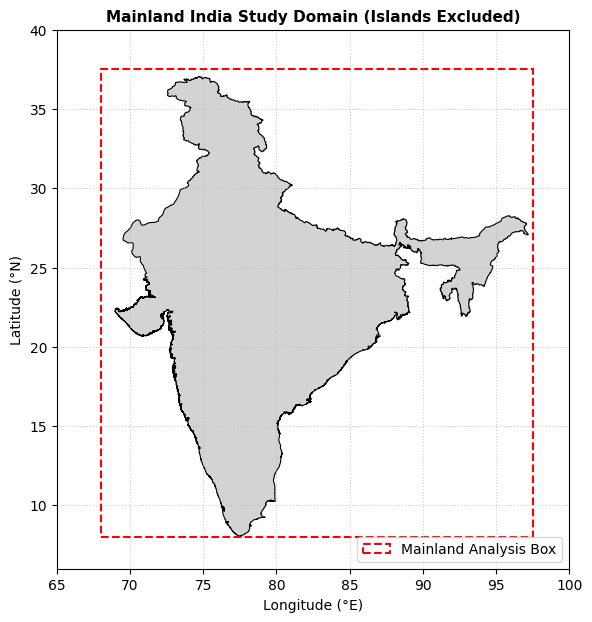

In [5]:
# Cell 2: Mainland India Domain (Islands Excluded) & Optimized Bounding Box
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# 1. Load India and Northern Territories
countries = ee.FeatureCollection('FAO/GAUL/2015/level0')
full_fc = countries.filter(ee.Filter.inList('ADM0_NAME', ['India', 'Jammu and Kashmir']))

# 2. Convert to GeoPandas DataFrame
india_geojson = full_fc.getInfo()
gdf_all = gpd.GeoDataFrame.from_features(india_geojson['features'], crs='EPSG:4326')

# 3. Filter out isolated islands (keep only mainland contiguous polygons with area > 10 sq degrees)
exploded = gdf_all.explode(index_parts=False)
gdf_mainland = exploded[exploded.geometry.area > 10.0].dissolve()

# 4. Derive exact mainland coordinate extremes
min_lon, min_lat, max_lon, max_lat = gdf_mainland.total_bounds
print("Exact Mainland India Extent (Verified):")
print(f"  South (Kanyakumari, Tamil Nadu) : {min_lat:.4f}° N")
print(f"  North (Ladakh / Siachen)        : {max_lat:.4f}° N")
print(f"  West  (Kutch, Gujarat)          : {min_lon:.4f}° E")
print(f"  East  (Arunachal Pradesh)       : {max_lon:.4f}° E")

# 5. Optimized Bounding Box for Mainland India (rounded outward by 0.5 degrees)
BBOX = [68.0, 8.0, 97.5, 37.5]  # [West, South, East, North]
india_bbox = ee.Geometry.BBox(*BBOX)
print(f"\nOptimized Mainland Bounding Box: Lon [{BBOX[0]}, {BBOX[2]}], Lat [{BBOX[1]}, {BBOX[3]}]")

# 6. Visual Verification Plot
fig, ax = plt.subplots(figsize=(7, 7))
gdf_mainland.plot(ax=ax, facecolor='lightgray', edgecolor='black', linewidth=0.8)

# Draw the optimized analysis bounding box
rect = patches.Rectangle(
    (BBOX[0], BBOX[1]), BBOX[2] - BBOX[0], BBOX[3] - BBOX[1],
    linewidth=1.5, edgecolor='red', facecolor='none', linestyle='--', label='Mainland Analysis Box'
)
ax.add_patch(rect)

ax.set_title("Mainland India Study Domain (Islands Excluded)", fontsize=11, fontweight='bold')
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.set_xlim(65, 100)
ax.set_ylim(6, 40)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='lower right')
plt.show()


In [7]:
# Cell 3: Exploring the MODIS MAIAC AOD Dataset (MCD19A2 v061)

# 1. Pick a sample date and filter to mainland India FIRST (fast query)
sample_date = '2023-01-01'
sample_col = ee.ImageCollection('MODIS/061/MCD19A2_GRANULES') \
    .filterDate(sample_date, '2023-01-02') \
    .filterBounds(india_bbox)

n_granules = sample_col.size().getInfo()
print(f"MODIS MAIAC Collection: 'MODIS/061/MCD19A2_GRANULES'")
print(f"Granules over Mainland India on {sample_date}: {n_granules}")

# 2. Inspect all band names from a single granule
first_img = sample_col.first()
band_info = first_img.bandNames().getInfo()
print(f"\nAvailable Bands ({len(band_info)} total):")
for b in band_info:
    print(f"  - {b}")

# 3. Explain the AOD_QA cloud mask bit structure
print("\n--- AOD_QA Cloud Mask (Bits 0-2) ---")
print("We extract bits 0-2 using: QA & 0b111 (i.e. QA & 7)")
qa_values = {
    0: "Undefined",
    1: "Clear  <-- WE KEEP ONLY THIS",
    2: "Possibly Cloudy (discard)",
    3: "Cloudy (discard)",
    5: "Cloud Shadow (discard)"
}
for val, desc in qa_values.items():
    print(f"  Value {val} ({val:03b}): {desc}")

# 4. Verify with real QA values from a 50km region around Delhi
delhi_point = ee.Geometry.Point(77.2, 28.6)
sample_qa = first_img.select('AOD_QA').reduceRegion(
    reducer=ee.Reducer.frequencyHistogram(),
    geometry=delhi_point.buffer(50000),
    scale=1000,
    maxPixels=1e6
).getInfo()

qa_hist = sample_qa.get('AOD_QA', {})
print(f"\n--- Real QA Distribution (50km around Delhi, {sample_date}) ---")
sorted_qa = sorted(qa_hist.items(), key=lambda x: -x[1])[:5]
for qa_str, count in sorted_qa:
    qa_int = int(qa_str)
    cloud_bits = qa_int & 0b111
    cloud_status = qa_values.get(cloud_bits, f"Other ({cloud_bits})")
    print(f"  QA={qa_int:5d} (cloud bits={cloud_bits}): {count:5d} pixels -> {cloud_status}")


MODIS MAIAC Collection: 'MODIS/061/MCD19A2_GRANULES'
Granules over Mainland India on 2023-01-01: 151

Available Bands (13 total):
  - Optical_Depth_047
  - Optical_Depth_055
  - AOD_Uncertainty
  - Column_WV
  - AOD_QA
  - Injection_Height
  - cosSZA
  - cosVZA
  - RelAZ
  - Scattering_Angle
  - Glint_Angle
  - FineModeFraction
  - AngstromExp_470-780

--- AOD_QA Cloud Mask (Bits 0-2) ---
We extract bits 0-2 using: QA & 0b111 (i.e. QA & 7)
  Value 0 (000): Undefined
  Value 1 (001): Clear  <-- WE KEEP ONLY THIS
  Value 2 (010): Possibly Cloudy (discard)
  Value 3 (011): Cloudy (discard)
  Value 5 (101): Cloud Shadow (discard)

--- Real QA Distribution (50km around Delhi, 2023-01-01) ---


Tile grid: 5 columns x 5 rows = 25 total tiles
Each tile: 5° x 5° (~555 km x ~555 km)


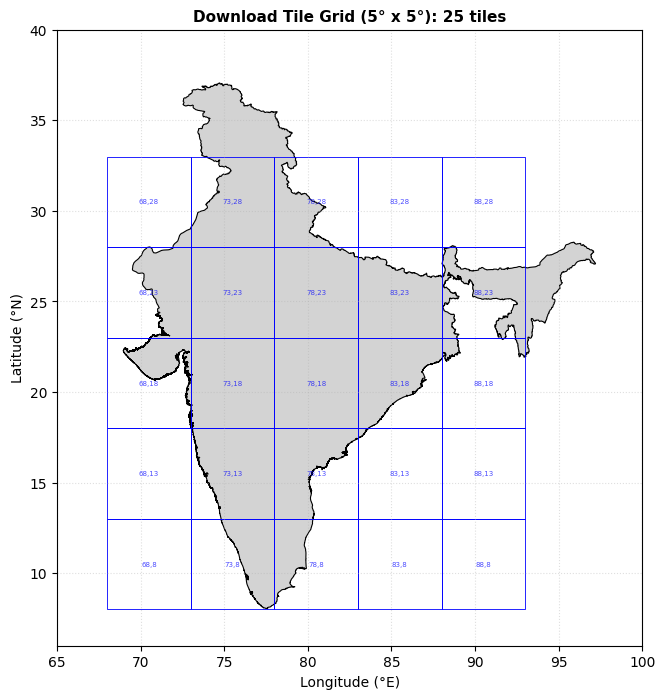


--- Test Download ---
Tile: lon73_lat23 (73.0-78.0°E, 23.0-28.0°N)
Date: 2023-01-01
Downloaded to: /home/mahtab/ADP/data/raw/test_tile_lon73_lat23_20230101.tif (596.3 KB)

Downloaded Tile Inspection:
  Grid Shape       : (557, 557) (rows x cols)
  CRS              : EPSG:4326
  Pixel Resolution : 0.008983° (~1.00 km)
  Lat Range        : [23.00, 28.00]
  Lon Range        : [73.00, 78.00]
  Valid AOD Pixels  : 308,799 (99.5%)
  Missing (Cloud)  : 1,450 (0.5%)
  AOD Range        : [0.014, 1.756]
  AOD Mean         : 0.420


In [8]:
# Cell 4: QA Masking Function, Tiling Scheme & Single-Tile Test Download
import urllib.request

# 1. Define the QA masking function (extracts clear-sky AOD only)
def get_daily_maiac_aod(date_str, region):
    """
    For a given date and region, fetch all MAIAC granules,
    apply QA cloud filtering, and composite into a single daily mean image.
    """
    # Next day string for date range filter
    from datetime import datetime, timedelta
    dt = datetime.strptime(date_str, '%Y-%m-%d')
    next_day = (dt + timedelta(days=1)).strftime('%Y-%m-%d')
    
    col = ee.ImageCollection('MODIS/061/MCD19A2_GRANULES') \
        .filterDate(date_str, next_day) \
        .filterBounds(region)
    
    def mask_qa(img):
        qa = img.select('AOD_QA')
        is_clear = qa.bitwiseAnd(7).eq(1)  # Bits 0-2 == 1 means Clear
        return img.select('Optical_Depth_055').multiply(0.001).updateMask(is_clear)
    
    # Apply QA mask to each granule, then take the daily mean of clear pixels
    daily_aod = col.map(mask_qa).mean().rename('aod_550')
    return daily_aod

# 2. Define a 5-degree x 5-degree tile grid over the India bounding box
import numpy as np

TILE_SIZE = 5  # degrees
lon_edges = np.arange(BBOX[0], BBOX[2] + 0.1, TILE_SIZE)  # 68, 73, 78, ..., 98
lat_edges = np.arange(BBOX[1], BBOX[3] + 0.1, TILE_SIZE)  # 8, 13, 18, ..., 38

tiles = []
for i in range(len(lon_edges) - 1):
    for j in range(len(lat_edges) - 1):
        tile = {
            'lon_min': lon_edges[i],
            'lon_max': lon_edges[i + 1],
            'lat_min': lat_edges[j],
            'lat_max': lat_edges[j + 1],
            'id': f"lon{lon_edges[i]:.0f}_lat{lat_edges[j]:.0f}"
        }
        tiles.append(tile)

print(f"Tile grid: {len(lon_edges)-1} columns x {len(lat_edges)-1} rows = {len(tiles)} total tiles")
print(f"Each tile: {TILE_SIZE}° x {TILE_SIZE}° (~{TILE_SIZE * 111:.0f} km x ~{TILE_SIZE * 111:.0f} km)")

# 3. Visualize the tile grid over India
fig, ax = plt.subplots(figsize=(8, 8))
gdf_mainland.plot(ax=ax, facecolor='lightgray', edgecolor='black', linewidth=0.8)

for t in tiles:
    rect = patches.Rectangle(
        (t['lon_min'], t['lat_min']), TILE_SIZE, TILE_SIZE,
        linewidth=0.6, edgecolor='blue', facecolor='none', linestyle='-'
    )
    ax.add_patch(rect)
    # Label each tile
    ax.text(t['lon_min'] + TILE_SIZE/2, t['lat_min'] + TILE_SIZE/2,
            t['id'].replace('lon','').replace('_lat',','), fontsize=5,
            ha='center', va='center', color='blue', alpha=0.7)

ax.set_title(f"Download Tile Grid ({TILE_SIZE}° x {TILE_SIZE}°): {len(tiles)} tiles", fontsize=11, fontweight='bold')
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.set_xlim(65, 100)
ax.set_ylim(6, 40)
ax.grid(True, linestyle=':', alpha=0.4)
plt.show()

# 4. Test download: ONE tile (North India / Delhi area), ONE day
test_tile = [t for t in tiles if t['lon_min'] == 73 and t['lat_min'] == 23][0]
test_date = '2023-01-01'
print(f"\n--- Test Download ---")
print(f"Tile: {test_tile['id']} ({test_tile['lon_min']}-{test_tile['lon_max']}°E, {test_tile['lat_min']}-{test_tile['lat_max']}°N)")
print(f"Date: {test_date}")

region = ee.Geometry.BBox(test_tile['lon_min'], test_tile['lat_min'],
                          test_tile['lon_max'], test_tile['lat_max'])
aod_img = get_daily_maiac_aod(test_date, region)

url = aod_img.getDownloadURL({
    'region': region,
    'scale': 1000,
    'format': 'GEO_TIFF'
})

test_path = os.path.join(DATA_RAW, f"test_tile_{test_tile['id']}_{test_date.replace('-','')}.tif")
urllib.request.urlretrieve(url, test_path)
print(f"Downloaded to: {test_path} ({os.path.getsize(test_path) / 1024:.1f} KB)")

# 5. Open and inspect the downloaded tile
da = rioxarray.open_rasterio(test_path)
data = da.values[0]
valid = data > 0
total_px = data.size
valid_px = int(np.count_nonzero(valid))
missing_pct = (1 - valid_px / total_px) * 100

print(f"\nDownloaded Tile Inspection:")
print(f"  Grid Shape       : {data.shape} (rows x cols)")
print(f"  CRS              : {da.rio.crs}")
print(f"  Pixel Resolution : {abs(da.rio.resolution()[0]):.6f}° (~{abs(da.rio.resolution()[0])*111:.2f} km)")
print(f"  Lat Range        : [{float(da.y.min()):.2f}, {float(da.y.max()):.2f}]")
print(f"  Lon Range        : [{float(da.x.min()):.2f}, {float(da.x.max()):.2f}]")
print(f"  Valid AOD Pixels  : {valid_px:,} ({100-missing_pct:.1f}%)")
print(f"  Missing (Cloud)  : {total_px - valid_px:,} ({missing_pct:.1f}%)")
if valid_px > 0:
    print(f"  AOD Range        : [{data[valid].min():.3f}, {data[valid].max():.3f}]")
    print(f"  AOD Mean         : {data[valid].mean():.3f}")


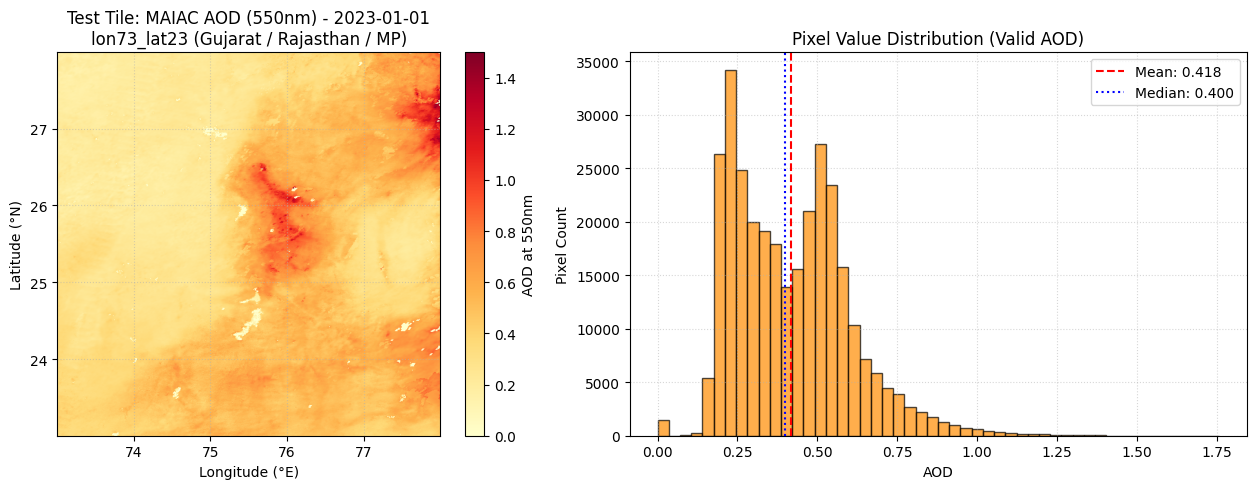

Total tiles generated across bounding box: 36 (36 possible)
Active tiles intersecting Mainland India: 24 (ocean tiles discarded)

Active Tile IDs:
  - lon68_lat18
  - lon68_lat23
  - lon68_lat28
  - lon73_lat8
  - lon73_lat13
  - lon73_lat18
  - lon73_lat23
  - lon73_lat28
  - lon73_lat33
  - lon78_lat8
  - lon78_lat13
  - lon78_lat18
  - lon78_lat23
  - lon78_lat28
  - lon78_lat33
  - lon83_lat13
  - lon83_lat18
  - lon83_lat23
  - lon88_lat18
  - lon88_lat23
  - lon88_lat28
  - lon93_lat18
  - lon93_lat23
  - lon93_lat28


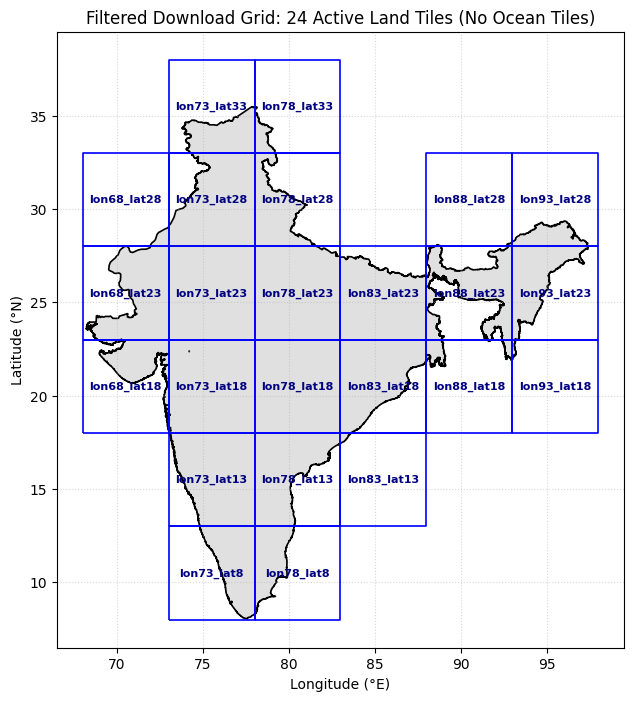

In [10]:
# Cell 5: Visualizing Test Tile & Filtering Grid to Mainland India Only
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import rioxarray
import geopandas as gpd
from shapely.geometry import box, shape

# =====================================================================
# 1. VISUALIZE THE DOWNLOADED TEST TILE (lon73_lat23)
# =====================================================================
tif_path = os.path.join(DATA_RAW, "test_tile_lon73_lat23_20230101.tif")
da = rioxarray.open_rasterio(tif_path).squeeze()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Spatial Map
im = axes[0].imshow(
    da.values,
    extent=[da.x.min().item(), da.x.max().item(), da.y.min().item(), da.y.max().item()],
    cmap="YlOrRd",
    vmin=0.0,
    vmax=1.5,
    origin="upper"
)
axes[0].set_title("Test Tile: MAIAC AOD (550nm) - 2023-01-01\nlon73_lat23 (Gujarat / Rajasthan / MP)")
axes[0].set_xlabel("Longitude (°E)")
axes[0].set_ylabel("Latitude (°N)")
axes[0].grid(True, linestyle=":", alpha=0.5)
plt.colorbar(im, ax=axes[0], label="AOD at 550nm", fraction=0.046, pad=0.04)

# (b) AOD Value Distribution Histogram
valid_vals = da.values[~np.isnan(da.values)]
axes[1].hist(valid_vals, bins=50, color="darkorange", edgecolor="black", alpha=0.7)
axes[1].axvline(valid_vals.mean(), color="red", linestyle="--", label=f"Mean: {valid_vals.mean():.3f}")
axes[1].axvline(np.median(valid_vals), color="blue", linestyle=":", label=f"Median: {np.median(valid_vals):.3f}")
axes[1].set_title("Pixel Value Distribution (Valid AOD)")
axes[1].set_xlabel("AOD")
axes[1].set_ylabel("Pixel Count")
axes[1].legend()
axes[1].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

# =====================================================================
# 2. LOAD MAINLAND INDIA POLYGON & FILTER ACTIVE TILES
# =====================================================================
# Fetch official boundary from Earth Engine LSIB
india_fc = ee.FeatureCollection("USDOS/LSIB_SIMPLE/2017").filter(ee.Filter.eq("country_na", "India"))
geojson_dict = india_fc.geometry().getInfo()
raw_geom = shape(geojson_dict)

# Select the largest polygon (mainland India, excluding islands)
if raw_geom.geom_type == "MultiPolygon":
    india_polygon = max(raw_geom.geoms, key=lambda p: p.area)
else:
    india_polygon = raw_geom

india_gdf = gpd.GeoDataFrame(geometry=[india_polygon], crs="EPSG:4326")

# Generate candidate 5°x5° bounding boxes across India's extent
raw_tiles = []
for lon_min in range(68, 98, 5):
    for lat_min in range(8, 38, 5):
        tile_box = box(lon_min, lat_min, lon_min + 5, lat_min + 5)
        # Keep only tiles that intersect the mainland India landmass
        if india_polygon.intersects(tile_box):
            raw_tiles.append({
                "tile_id": f"lon{lon_min}_lat{lat_min}",
                "bbox": [lon_min, lat_min, lon_min + 5, lat_min + 5],
                "geometry": tile_box
            })

tiles_gdf = gpd.GeoDataFrame(raw_tiles, geometry="geometry", crs="EPSG:4326")

print(f"Total tiles generated across bounding box: {6 * 6} (36 possible)")
print(f"Active tiles intersecting Mainland India: {len(tiles_gdf)} (ocean tiles discarded)")
print("\nActive Tile IDs:")
for t in tiles_gdf["tile_id"]:
    print(f"  - {t}")

# Visualize the filtered grid
fig, ax = plt.subplots(figsize=(8, 8))
india_gdf.plot(ax=ax, color="#e0e0e0", edgecolor="black", linewidth=1.2)
tiles_gdf.boundary.plot(ax=ax, color="blue", linewidth=1.2)

for idx, row in tiles_gdf.iterrows():
    b = row["bbox"]
    ax.text((b[0] + b[2]) / 2, (b[1] + b[3]) / 2, row["tile_id"],
            fontsize=8, ha="center", va="center", color="navy", weight="bold")

ax.set_title(f"Filtered Download Grid: {len(tiles_gdf)} Active Land Tiles (No Ocean Tiles)")
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.grid(True, linestyle=":", alpha=0.5)
plt.show()


--- Downloading Auxiliary Stack ---
Tile: lon73_lat23 (73-78°E, 23-28°N)
Date: 2023-01-01
File verified at: /home/mahtab/ADP/data/raw/test_tile_lon73_lat23_20230101_aux.tif (765.8 KB)

Auxiliary Raster Inspection:
  Shape (bands, rows, cols) : (7, 557, 557)
  CRS                       : EPSG:4326
  Resolution                : 0.008983° (~1.0 km)

Band Verification:
  [1] Temperature (2m)    : Range=[284.91, 292.45], Missing=0 (0.0%)
  [2] Dewpoint Temp (2m)  : Range=[274.57, 282.83], Missing=0 (0.0%)
  [3] Surface Pressure    : Range=[92638.75, 101016.84], Missing=0 (0.0%)
  [4] Wind U (10m)        : Range=[-2.11, 0.55], Missing=0 (0.0%)
  [5] Wind V (10m)        : Range=[-1.80, 1.07], Missing=0 (0.0%)
  [6] Total Precipitation : Range=[0.00, 0.00], Missing=0 (0.0%)
  [7] Elevation (DEM)     : Range=[66.00, 1147.00], Missing=0 (0.0%)


Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.


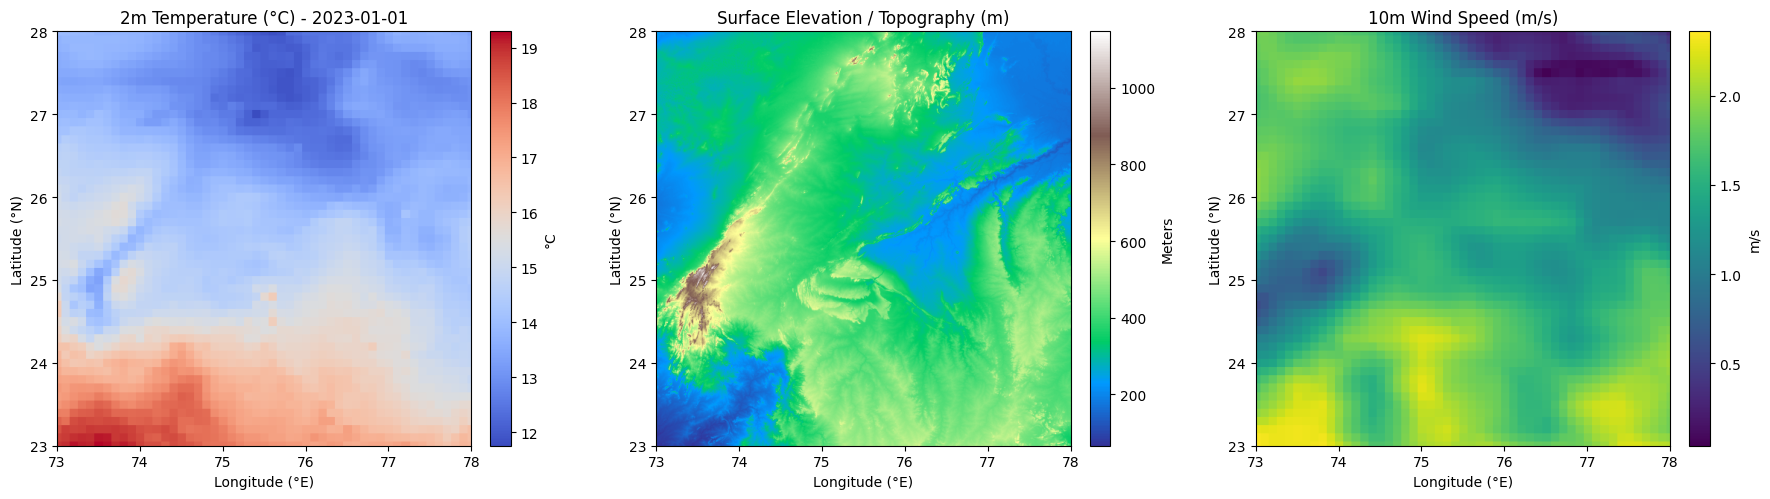

In [12]:
# Cell 6: Extract, Align & Inspect Gap-Free Auxiliary Features (ERA5-Land & SRTM DEM)
import os
import urllib.request
from datetime import datetime, timedelta
import numpy as np
import matplotlib.pyplot as plt
import rioxarray

# =====================================================================
# 1. DEFINE AUXILIARY EXTRACTION FROM GOOGLE EARTH ENGINE
# =====================================================================
def get_daily_aux_stack(date_str, region_geom):
    """
    Extracts daily ERA5-Land meteorology and SRTM elevation,
    resampled and aligned at 1 km resolution.
    """
    # Pure Python date math (instant, zero network latency)
    d = datetime.strptime(date_str, "%Y-%m-%d")
    next_day = (d + timedelta(days=1)).strftime("%Y-%m-%d")
    
    # 1. ERA5-Land Daily Aggregate for target date
    era5 = ee.ImageCollection('ECMWF/ERA5_LAND/DAILY_AGGR') \
        .filterDate(date_str, next_day) \
        .first() \
        .select([
            'temperature_2m', 
            'dewpoint_temperature_2m', 
            'surface_pressure', 
            'u_component_of_wind_10m', 
            'v_component_of_wind_10m', 
            'total_precipitation_sum'
        ])
    
    # 2. SRTM 30m Digital Elevation Model (Static Topography)
    dem = ee.Image('USGS/SRTMGL1_003').select('elevation')
    
    # Combine meteorology + elevation into a single 7-band raster
    aux_stack = era5.addBands(dem)
    return aux_stack

# =====================================================================
# 2. TEST-DOWNLOAD AUXILIARY STACK FOR TEST TILE (lon73_lat23)
# =====================================================================
test_tile = [t for t in raw_tiles if t["tile_id"] == "lon73_lat23"][0]
test_date = "2023-01-01"
b = test_tile["bbox"]
region = ee.Geometry.BBox(b[0], b[1], b[2], b[3])
aux_path = os.path.join(DATA_RAW, f"test_tile_{test_tile['tile_id']}_{test_date.replace('-','')}_aux.tif")

print(f"--- Downloading Auxiliary Stack ---")
print(f"Tile: {test_tile['tile_id']} ({b[0]}-{b[2]}°E, {b[1]}-{b[3]}°N)")
print(f"Date: {test_date}")

# Only download from GEE if not already cached locally
if not os.path.exists(aux_path):
    aux_img = get_daily_aux_stack(test_date, region)
    aux_url = aux_img.getDownloadURL({
        'region': region,
        'scale': 1000,
        'format': 'GEO_TIFF'
    })
    urllib.request.urlretrieve(aux_url, aux_path)

print(f"File verified at: {aux_path} ({os.path.getsize(aux_path) / 1024:.1f} KB)")

# =====================================================================
# 3. VERIFY ALIGNMENT & GAP-FREE PROPERTIES
# =====================================================================
aux_da = rioxarray.open_rasterio(aux_path)
print(f"\nAuxiliary Raster Inspection:")
print(f"  Shape (bands, rows, cols) : {aux_da.shape}")
print(f"  CRS                       : {aux_da.rio.crs}")
print(f"  Resolution                : {abs(aux_da.rio.resolution()[0]):.6f}° (~1.0 km)")

band_names = [
    "Temperature (2m)", 
    "Dewpoint Temp (2m)", 
    "Surface Pressure", 
    "Wind U (10m)", 
    "Wind V (10m)", 
    "Total Precipitation", 
    "Elevation (DEM)"
]

print("\nBand Verification:")
for i, name in enumerate(band_names):
    arr = aux_da.values[i]
    missing = np.count_nonzero(np.isnan(arr))
    pct_missing = (missing / arr.size) * 100
    print(f"  [{i+1}] {name:<20}: Range=[{np.nanmin(arr):.2f}, {np.nanmax(arr):.2f}], Missing={missing} ({pct_missing:.1f}%)")

# =====================================================================
# 4. VISUALIZE SATELLITE AOD VS. GAP-FREE PREDICTORS
# =====================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (a) Temperature 2m (in Celsius)
temp_c = aux_da.values[0] - 273.15
im0 = axes[0].imshow(temp_c, extent=[b[0], b[2], b[1], b[3]], cmap="coolwarm", origin="upper")
axes[0].set_title(f"2m Temperature (°C) - {test_date}")
axes[0].set_xlabel("Longitude (°E)")
axes[0].set_ylabel("Latitude (°N)")
plt.colorbar(im0, ax=axes[0], label="°C", fraction=0.046, pad=0.04)

# (b) Surface Elevation (meters above sea level)
elev = aux_da.values[6]
im1 = axes[1].imshow(elev, extent=[b[0], b[2], b[1], b[3]], cmap="terrain", origin="upper")
axes[1].set_title("Surface Elevation / Topography (m)")
axes[1].set_xlabel("Longitude (°E)")
axes[1].set_ylabel("Latitude (°N)")
plt.colorbar(im1, ax=axes[1], label="Meters", fraction=0.046, pad=0.04)

# (c) Wind Speed (calculated from U and V components)
u_wind = aux_da.values[3]
v_wind = aux_da.values[4]
wind_speed = np.sqrt(u_wind**2 + v_wind**2)
im2 = axes[2].imshow(wind_speed, extent=[b[0], b[2], b[1], b[3]], cmap="viridis", origin="upper")
axes[2].set_title("10m Wind Speed (m/s)")
axes[2].set_xlabel("Longitude (°E)")
axes[2].set_ylabel("Latitude (°N)")
plt.colorbar(im2, ax=axes[2], label="m/s", fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


--- NASA Earthdata Authentication ---

Searching MERRA-2 for date: 2023-01-01...


QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 975.65it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:38<00:00, 38.37s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 4048.56it/s]


Downloaded MERRA-2 file: /home/mahtab/ADP/data/raw/merra2/MERRA2_400.tavg1_2d_aer_Nx.20230101.nc4

MERRA-2 Grid Inspection:
  Coarse Shape (lat x lon) : (65, 48)
  Latitude Resolution      : 0.500° (~50 km)
  Longitude Resolution     : 0.625° (~60 km)
  AOD (550nm) Range         : [0.008, 1.679]
  Missing Pixels            : 0 (100% gap-free)

Downscaled MERRA-2 Inspection:
  Target Shape (rows x cols): (557, 557) (exactly matches 1km MAIAC tile)
  Downscaled AOD Mean       : 0.207


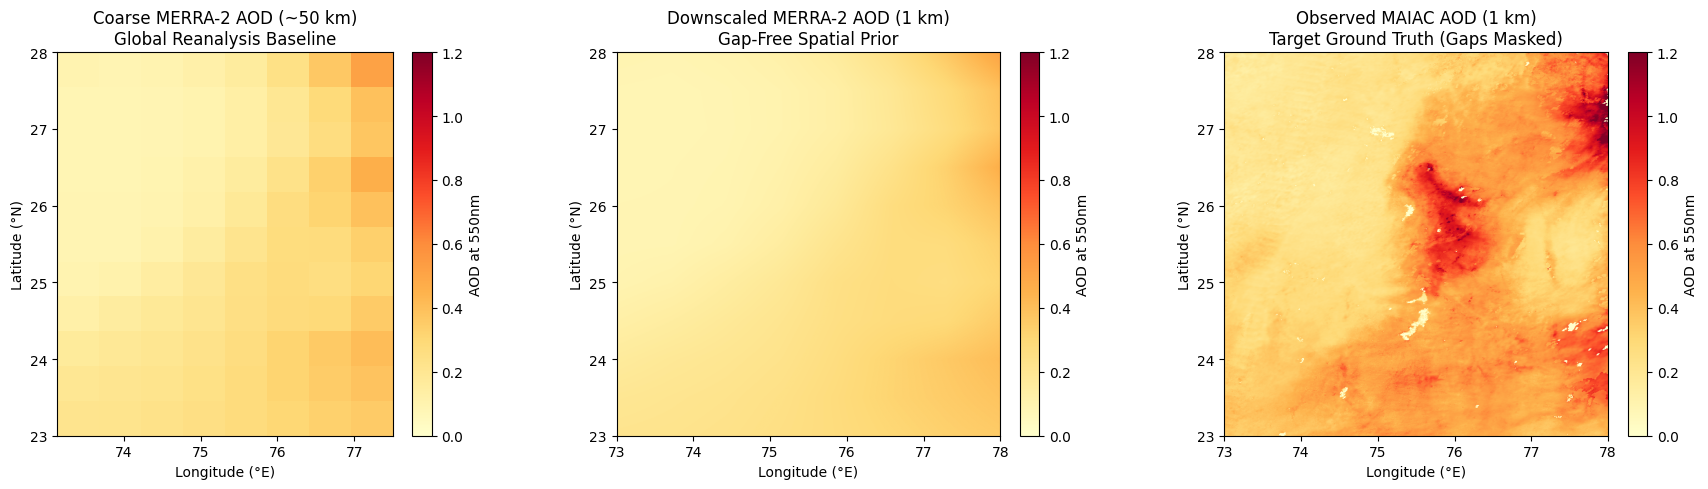

In [15]:
# Cell 7: Ingesting & Downscaling NASA MERRA-2 Aerosol Reanalysis
import os
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import earthaccess

# =====================================================================
# 1. AUTHENTICATE WITH NASA EARTHDATA
# =====================================================================
# Prompts for your Earthdata credentials once and persists them in ~/.netrc
print("--- NASA Earthdata Authentication ---")
auth = earthaccess.login(persist=True)
if not auth.authenticated:
    print("Please log in with your free NASA Earthdata account (urs.earthdata.nasa.gov)")

# =====================================================================
# 2. QUERY & DOWNLOAD DAILY MERRA-2 AEROSOL FILE (M2T1NXAER)
# =====================================================================
test_date = "2023-01-01"
print(f"\nSearching MERRA-2 for date: {test_date}...")

results = earthaccess.search_data(
    short_name="M2T1NXAER",
    temporal=(test_date, test_date),
    count=1
)

merra_dir = os.path.join(DATA_RAW, "merra2")
os.makedirs(merra_dir, exist_ok=True)

# Download daily NetCDF file
downloaded_files = earthaccess.download(results, merra_dir)
merra_nc_path = downloaded_files[0]
print(f"Downloaded MERRA-2 file: {merra_nc_path}")

# =====================================================================
# 3. OPEN MERRA-2 & EXTRACT DAILY MEAN 550nm AOD (TOTEXTTAU)
# =====================================================================
ds_merra = xr.open_dataset(merra_nc_path)

# TOTEXTTAU: Total Aerosol Optical Depth at 550nm (daily mean across time dimension)
daily_aod = ds_merra["TOTEXTTAU"].mean(dim="time")

# Crop to India Bounding Box with buffer [lat: 6 to 38, lon: 68 to 98]
india_merra = daily_aod.sel(
    lat=slice(6.0, 38.0),
    lon=slice(68.0, 98.0)
)

print(f"\nMERRA-2 Grid Inspection:")
print(f"  Coarse Shape (lat x lon) : {india_merra.shape}")
print(f"  Latitude Resolution      : {abs(india_merra.lat.values[1] - india_merra.lat.values[0]):.3f}° (~50 km)")
print(f"  Longitude Resolution     : {abs(india_merra.lon.values[1] - india_merra.lon.values[0]):.3f}° (~60 km)")
print(f"  AOD (550nm) Range         : [{india_merra.values.min():.3f}, {india_merra.values.max():.3f}]")
print(f"  Missing Pixels            : {np.count_nonzero(np.isnan(india_merra.values))} (100% gap-free)")

# =====================================================================
# 4. DOWNSCALE MERRA-2 TO OUR 1-KM TEST TILE GRID (lon73_lat23)
# =====================================================================
# Load target coordinate grid from test MAIAC tile
test_aod_path = os.path.join(DATA_RAW, "test_tile_lon73_lat23_20230101.tif")
target_da = rioxarray.open_rasterio(test_aod_path).squeeze()
target_shape = target_da.shape  # (rows, cols) = (557, 557)

# Crop MERRA-2 specifically over the test tile bounds [73-78°E, 23-28°N]
tile_merra = daily_aod.sel(lat=slice(23.0, 28.0), lon=slice(73.0, 78.0))

# PyTorch Bilinear Interpolation (fast, exact, GPU-ready)
merra_tensor = torch.tensor(tile_merra.values, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
downscaled_tensor = F.interpolate(
    merra_tensor,
    size=target_shape,
    mode="bilinear",
    align_corners=True
)
downscaled_merra_aod = np.flipud(downscaled_tensor.squeeze().numpy())

print(f"\nDownscaled MERRA-2 Inspection:")
print(f"  Target Shape (rows x cols): {downscaled_merra_aod.shape} (exactly matches 1km MAIAC tile)")
print(f"  Downscaled AOD Mean       : {downscaled_merra_aod.mean():.3f}")

# =====================================================================
# 5. VISUALIZE MULTISCALE AEROSOL COMPARISON
# =====================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
b = [73.0, 23.0, 78.0, 28.0]

# (a) Coarse MERRA-2 crop over the tile region
im0 = axes[0].imshow(
    tile_merra.values,
    extent=[tile_merra.lon.min(), tile_merra.lon.max(), tile_merra.lat.min(), tile_merra.lat.max()],
    cmap="YlOrRd", vmin=0.0, vmax=1.2, origin="lower"
)
axes[0].set_title("Coarse MERRA-2 AOD (~50 km)\nGlobal Reanalysis Baseline")
axes[0].set_xlabel("Longitude (°E)")
axes[0].set_ylabel("Latitude (°N)")
plt.colorbar(im0, ax=axes[0], label="AOD at 550nm", fraction=0.046, pad=0.04)

# (b) Downscaled MERRA-2 AOD (1 km continuous grid)
im1 = axes[1].imshow(
    downscaled_merra_aod,
    extent=[b[0], b[2], b[1], b[3]],
    cmap="YlOrRd", vmin=0.0, vmax=1.2, origin="upper"
)
axes[1].set_title("Downscaled MERRA-2 AOD (1 km)\nGap-Free Spatial Prior")
axes[1].set_xlabel("Longitude (°E)")
axes[1].set_ylabel("Latitude (°N)")
plt.colorbar(im1, ax=axes[1], label="AOD at 550nm", fraction=0.046, pad=0.04)

# (c) High-Res Satellite MAIAC AOD (1 km with cloud gaps)
im2 = axes[2].imshow(
    target_da.values,
    extent=[b[0], b[2], b[1], b[3]],
    cmap="YlOrRd", vmin=0.0, vmax=1.2, origin="upper"
)
axes[2].set_title("Observed MAIAC AOD (1 km)\nTarget Ground Truth (Gaps Masked)")
axes[2].set_xlabel("Longitude (°E)")
axes[2].set_ylabel("Latitude (°N)")
plt.colorbar(im2, ax=axes[2], label="AOD at 550nm", fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


In [16]:
# Cell 8: Packaging Unified Multi-Modal Training Tensors (.npz)
import os
import numpy as np
import rioxarray
import xarray as xr
import torch
import torch.nn.functional as F

# =====================================================================
# 1. DEFINE UNIFIED SAMPLE BUILDER FUNCTION
# =====================================================================
def build_and_save_tile_sample(tile_id, date_str, maiac_tif, aux_tif, merra_nc, output_dir):
    """
    Combines MAIAC satellite AOD, ERA5 meteorology, SRTM DEM, and MERRA-2
    into a standardized PyTorch-ready compressed .npz archive.
    """
    os.makedirs(output_dir, exist_ok=True)
    out_path = os.path.join(output_dir, f"tile_{tile_id}_{date_str.replace('-','')}.npz")
    
    # 1. Load Observed MAIAC AOD (Target)
    da_maiac = rioxarray.open_rasterio(maiac_tif).squeeze()
    target_aod = da_maiac.values.astype(np.float32)
    # Valid observation mask (1 = clear sky observation, 0 = cloud/missing)
    obs_mask = (~np.isnan(target_aod) & (target_aod > 0)).astype(np.uint8)
    
    # 2. Load ERA5-Land Meteorology + SRTM DEM (7 channels)
    da_aux = rioxarray.open_rasterio(aux_tif)
    aux_feats = da_aux.values.astype(np.float32)  # shape: (7, rows, cols)
    
    # 3. Load & Downscale MERRA-2 AOD Prior (1 channel)
    ds_merra = xr.open_dataset(merra_nc)
    daily_merra = ds_merra["TOTEXTTAU"].mean(dim="time")
    
    # Bounding box coordinates from tile ID
    # e.g., 'lon73_lat23' -> lon: [73, 78], lat: [23, 28]
    parts = tile_id.split('_')
    lon_min = float(parts[0].replace('lon', ''))
    lat_min = float(parts[1].replace('lat', ''))
    
    tile_merra = daily_merra.sel(
        lat=slice(lat_min, lat_min + 5.0),
        lon=slice(lon_min, lon_min + 5.0)
    )
    
    merra_t = torch.tensor(tile_merra.values, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
    downscaled_merra = F.interpolate(
        merra_t,
        size=target_aod.shape,
        mode="bilinear",
        align_corners=True
    )
    merra_feat = np.flipud(downscaled_merra.squeeze().numpy())
    
    # 4. Stack All Features: Channel 0 (MERRA-2) + Channels 1-7 (ERA5 + DEM)
    feature_stack = np.vstack([merra_feat[np.newaxis, :, :], aux_feats])  # shape: (8, rows, cols)
    
    # 5. Save compressed .npz archive
    np.savez_compressed(
        out_path,
        features=feature_stack,                     # (8, H, W)
        target=target_aod[np.newaxis, :, :],        # (1, H, W)
        mask=obs_mask[np.newaxis, :, :],            # (1, H, W)
        bbox=np.array([lon_min, lat_min, lon_min + 5.0, lat_min + 5.0], dtype=np.float32)
    )
    
    return out_path

# =====================================================================
# 2. TEST-BUILD ON OUR VERIFIED SAMPLE TILE
# =====================================================================
test_tile_id = "lon73_lat23"
test_date = "2023-01-01"

maiac_tif = os.path.join(DATA_RAW, f"test_tile_{test_tile_id}_{test_date.replace('-','')}.tif")
aux_tif   = os.path.join(DATA_RAW, f"test_tile_{test_tile_id}_{test_date.replace('-','')}_aux.tif")
merra_nc  = os.path.join(DATA_RAW, "merra2", f"MERRA2_400.tavg1_2d_aer_Nx.{test_date.replace('-','')}.nc4")

print(f"--- Packaging Multi-Modal Tensor Sample ---")
npz_file = build_and_save_tile_sample(
    tile_id=test_tile_id,
    date_str=test_date,
    maiac_tif=maiac_tif,
    aux_tif=aux_tif,
    merra_nc=merra_nc,
    output_dir=DATA_PROCESSED
)

print(f"Sample saved to: {npz_file} ({os.path.getsize(npz_file) / (1024*1024):.2f} MB)")

# =====================================================================
# 3. VERIFY RELOAD & TENSOR SHAPES
# =====================================================================
sample = np.load(npz_file)
print(f"\n--- Unified Sample Verification ---")
print(f"  Feature Tensor (X)  : Shape = {sample['features'].shape} (8 channels x {sample['features'].shape[1]} x {sample['features'].shape[2]})")
print(f"  Target Tensor (Y)   : Shape = {sample['target'].shape} (1 channel x {sample['target'].shape[1]} x {sample['target'].shape[2]})")
print(f"  Observation Mask (M): Shape = {sample['mask'].shape} (1 channel x {sample['mask'].shape[1]} x {sample['mask'].shape[2]})")
print(f"  Bounding Box        : {sample['bbox'].tolist()}")

channel_names = [
    "MERRA-2 AOD (550nm)",
    "ERA5 2m Temperature (K)",
    "ERA5 2m Dewpoint (K)",
    "ERA5 Surface Pressure (Pa)",
    "ERA5 10m Wind U (m/s)",
    "ERA5 10m Wind V (m/s)",
    "ERA5 Total Precipitation (m)",
    "SRTM DEM Elevation (m)"
]

print(f"\nChannel Breakdown & Integrity:")
for idx, name in enumerate(channel_names):
    ch_data = sample['features'][idx]
    print(f"  Ch {idx}: {name:<28} | Range=[{ch_data.min():.2f}, {ch_data.max():.2f}] | Mean={ch_data.mean():.2f}")


--- Packaging Multi-Modal Tensor Sample ---


Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.


Sample saved to: /home/mahtab/ADP/data/processed/tile_lon73_lat23_20230101.npz (1.96 MB)

--- Unified Sample Verification ---
  Feature Tensor (X)  : Shape = (8, 557, 557) (8 channels x 557 x 557)
  Target Tensor (Y)   : Shape = (1, 557, 557) (1 channel x 557 x 557)
  Observation Mask (M): Shape = (1, 557, 557) (1 channel x 557 x 557)
  Bounding Box        : [73.0, 23.0, 78.0, 28.0]

Channel Breakdown & Integrity:
  Ch 0: MERRA-2 AOD (550nm)          | Range=[0.08, 0.51] | Mean=0.21
  Ch 1: ERA5 2m Temperature (K)      | Range=[284.91, 292.45] | Mean=287.84
  Ch 2: ERA5 2m Dewpoint (K)         | Range=[274.57, 282.83] | Mean=278.96
  Ch 3: ERA5 Surface Pressure (Pa)   | Range=[92638.75, 101016.84] | Mean=97746.41
  Ch 4: ERA5 10m Wind U (m/s)        | Range=[-2.11, 0.55] | Mean=-1.25
  Ch 5: ERA5 10m Wind V (m/s)        | Range=[-1.80, 1.07] | Mean=-0.50
  Ch 6: ERA5 Total Precipitation (m) | Range=[0.00, 0.00] | Mean=0.00
  Ch 7: SRTM DEM Elevation (m)       | Range=[66.00, 1147.00] |

In [17]:
# Cell 9: PyTorch Dataset, Feature Normalizer & GPU DataLoader
import glob
import torch
from torch.utils.data import Dataset, DataLoader
import numpy as np

# =====================================================================
# 1. CHANNEL NORMALIZATION CONSTANTS (Physical Min & Max / Scales)
# =====================================================================
# Standardizing features to ~[0, 1] keeps neural network gradients stable
FEATURE_MEANS = np.array([0.25, 290.0, 280.0, 98000.0, 0.0, 0.0, 0.001, 300.0], dtype=np.float32)
FEATURE_STDS  = np.array([0.25,  15.0,  15.0,  5000.0, 3.0, 3.0, 0.010, 500.0], dtype=np.float32)

def normalize_features(features):
    """Broadcasting Z-score normalization: (C, H, W)"""
    return (features - FEATURE_MEANS[:, None, None]) / FEATURE_STDS[:, None, None]

# =====================================================================
# 2. DEFINE PYTORCH DATASET CLASS
# =====================================================================
class AODImputationDataset(Dataset):
    def __init__(self, npz_paths, patch_size=128, random_crop=True):
        self.npz_paths = npz_paths
        self.patch_size = patch_size
        self.random_crop = random_crop

    def __len__(self):
        return len(self.npz_paths)

    def __getitem__(self, idx):
        # 1. Fast load from compressed disk (.npz)
        data = np.load(self.npz_paths[idx])
        features = data['features']   # (8, H, W)
        target   = data['target']     # (1, H, W)
        mask     = data['mask']       # (1, H, W)

        # 2. Normalize features
        features = normalize_features(features)

        # 3. Spatial Patch Cropping (H, W) -> (patch_size, patch_size)
        H, W = features.shape[1], features.shape[2]
        if self.patch_size is not None and self.patch_size < H and self.patch_size < W:
            if self.random_crop:
                top = np.random.randint(0, H - self.patch_size + 1)
                left = np.random.randint(0, W - self.patch_size + 1)
            else:
                top = (H - self.patch_size) // 2
                left = (W - self.patch_size) // 2

            features = features[:, top:top+self.patch_size, left:left+self.patch_size]
            target   = target[:, top:top+self.patch_size, left:left+self.patch_size]
            mask     = mask[:, top:top+self.patch_size, left:left+self.patch_size]

        # 4. Convert to PyTorch Tensors
        # Fill missing NaN target values with 0.0 so tensors are pure numbers
        clean_target = np.nan_to_num(target, nan=0.0)

        return {
            'features': torch.from_numpy(features).float(),
            'target': torch.from_numpy(clean_target).float(),
            'mask': torch.from_numpy(mask).float()
        }

# =====================================================================
# 3. VERIFY DATALOADER ON RTX 4050 GPU
# =====================================================================
processed_files = glob.glob(os.path.join(DATA_PROCESSED, "*.npz"))
print(f"Total processed samples found: {len(processed_files)}")

dataset = AODImputationDataset(processed_files, patch_size=128, random_crop=True)
dataloader = DataLoader(dataset, batch_size=2, shuffle=True)

# Fetch one sample batch and test GPU transfer
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\nStreaming sample batch to device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})...")

for batch in dataloader:
    x = batch['features'].to(device)
    y = batch['target'].to(device)
    m = batch['mask'].to(device)

    print(f"\nPyTorch Batch Shapes:")
    print(f"  Input Features (X) : {x.shape}  [Batch, Channels=8, Height=128, Width=128]")
    print(f"  Target AOD (Y)     : {y.shape}  [Batch, Channels=1, Height=128, Width=128]")
    print(f"  Valid Mask (M)     : {m.shape}  [Batch, Channels=1, Height=128, Width=128]")
    print(f"  Batch Device       : {x.device}")
    print(f"  Normalized X Range : [{x.min().item():.2f}, {x.max().item():.2f}]")
    print(f"  Target AOD Range   : [{y.min().item():.2f}, {y.max().item():.2f}]")
    print(f"  Observed Pixels %  : {(m.sum() / m.numel()).item() * 100:.1f}%")
    break

print("\n--- PHASE 1 (DATASET INGESTION & PIPELINE) COMPLETE ---")


Total processed samples found: 1

Streaming sample batch to device: cuda (NVIDIA GeForce RTX 4050 Laptop GPU)...

PyTorch Batch Shapes:
  Input Features (X) : torch.Size([1, 8, 128, 128])  [Batch, Channels=8, Height=128, Width=128]
  Target AOD (Y)     : torch.Size([1, 1, 128, 128])  [Batch, Channels=1, Height=128, Width=128]
  Valid Mask (M)     : torch.Size([1, 1, 128, 128])  [Batch, Channels=1, Height=128, Width=128]
  Batch Device       : cuda:0
  Normalized X Range : [-0.69, 0.53]
  Target AOD Range   : [0.00, 0.91]
  Observed Pixels %  : 97.8%

--- PHASE 1 (DATASET INGESTION & PIPELINE) COMPLETE ---
